# Zomato restaurant listings in Bengaluru

Where should a restaurant discovery platform start recruiting partners, and what should its locality pages show? Each observation in the analysis is an outlet, identified by normalized restaurant name and address. The data describe listed supply. Customer demand would require searches, bookings or order logs.

[Assigned Kaggle dataset](https://www.kaggle.com/datasets/bhanupratapbiswas/zomato)

## Load the assigned data
Run the notebook from top to bottom. The first run downloads the public Kaggle ZIP. For offline use, place the same archive at `data/zomato.zip` beside the notebook.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import Request, urlopen
from zipfile import ZipFile
from hashlib import sha256

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TEAL, AMBER = "#187c77", "#bd6b32"
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlepad": 12})
slug = 'zomato'
archive = Path("data") / (slug + ".zip")
if not archive.is_file():
    archive.parent.mkdir(parents=True, exist_ok=True)
    url = "https://api.kaggle.com/v1/datasets/download/bhanupratapbiswas/" + slug
    with urlopen(Request(url, headers={"User-Agent": "Alfido-coursework/1.0"}), timeout=120) as response:
        payload = response.read()
    with ZipFile(BytesIO(payload)) as downloaded:
        assert downloaded.testzip() is None, "Incomplete dataset archive"
    archive.write_bytes(payload)

# Fingerprints identify the exact source tables used for the saved results.
expected = {'zomato.csv': '18cefe3655e39c7a0105c48fd8b654ea9a32bd0f8715c4f8fea52005c3ab7ac1'}

def read_table(filename):
    with ZipFile(archive) as source:
        content = source.read(filename)
    if sha256(content).hexdigest() != expected[filename]:
        raise ValueError(f"{filename} differs from the snapshot used for this report.")
    return pd.read_csv(BytesIO(content))

def profile(frame):
    return pd.DataFrame({"data_type": frame.dtypes.astype(str), "missing": frame.isna().sum(),
                         "distinct_values": frame.nunique()})

## Inspect the source rows
The CSV includes restaurant listings and fragments of text in the same columns. The audit below checks missing fields and the two yes/no fields before making numerical comparisons.

In [2]:
raw = read_table("zomato.csv")
display(profile(raw))
flags = raw[["online_order", "book_table"]].apply(lambda s: s.str.strip().str.casefold())
valid = flags.isin(["yes", "no"]).all(axis=1)
print(f"Source rows: {len(raw):,}. Rows outside the two-field listing schema: {(~valid).sum():,}.")
print(f"Repeated identical rows among valid listings: {raw[valid].duplicated().sum():,}.")

,data_type,missing,distinct_values
address,object,17,13397
name,object,16,11914
online_order,object,19,2639
book_table,object,58,2902
rate,object,7838,2877
votes,object,78,5195
phone,object,1296,17712
location,object,126,2920
rest_type,object,338,2961
dish_liked,object,28225,8067


Source rows: 56,252. Rows outside the two-field listing schema: 4,535.
Repeated identical rows among valid listings: 15,315.


## Reconcile repeat listings
Keep one exact row per listing first. An outlet can still appear under several listing categories with different vote totals. Choose the observation with the most votes for each name/address, using source order to break ties. This is a reproducible representative observation because the source has no observation dates. A missing or NEW rating stays missing. The listed price is the approximate cost for two in Indian rupees.

In [3]:
listings = raw.loc[valid].drop_duplicates().copy()
for col in ["name", "address", "location", "cuisines"]:
    listings[col] = listings[col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
listings = listings.dropna(subset=["name", "address"])
listings["outlet_name"] = listings["name"].str.casefold()
listings["outlet_address"] = listings["address"].str.casefold()
listings["votes"] = pd.to_numeric(listings["votes"], errors="coerce")
rating_text = listings["rate"].str.extract(r"^\s*([0-5](?:\.\d+)?)\s*/\s*5\s*$", expand=False)
listings["rating"] = pd.to_numeric(rating_text, errors="coerce")
listings["rating"] = listings["rating"].where(listings["rating"].between(1, 5))
cost = pd.to_numeric(listings["approx_cost(for two people)"].str.replace(",", "", regex=False), errors="coerce")
listings["cost_for_two_inr"] = cost.where(cost.gt(0))
outlets = (listings.sort_values("votes", ascending=False, kind="stable")
          .drop_duplicates(["outlet_name", "outlet_address"])
          .loc[:, ["name", "location", "cuisines", "rating", "votes", "cost_for_two_inr"]]
          .reset_index(drop=True).rename_axis("outlet_id"))
assert outlets["rating"].dropna().between(1, 5).all()
outlets.to_csv("cleaned_outlets.csv", encoding="utf-8", lineterminator="\n")
print(f"{len(outlets):,} outlets; {outlets.rating.count():,} rated; {outlets.cost_for_two_inr.count():,} priced.")
display(outlets[["rating", "votes", "cost_for_two_inr"]].describe().round(2))

12,494 outlets; 9,478 rated; 12,428 priced.


,rating,votes,cost_for_two_inr
count,9478.00,12494.00,12428.00
mean,3.63,183.88,488.07
std,0.43,599.25,391.70
min,1.80,0.00,40.00
25%,3.30,4.00,250.00
50%,3.70,25.00,400.00
75%,3.90,123.00,600.00
max,4.90,16832.00,6000.00


## Which localities have the most listings?
Count distinct outlets whether or not they have a rating. Missing locality values are excluded from this ranking.

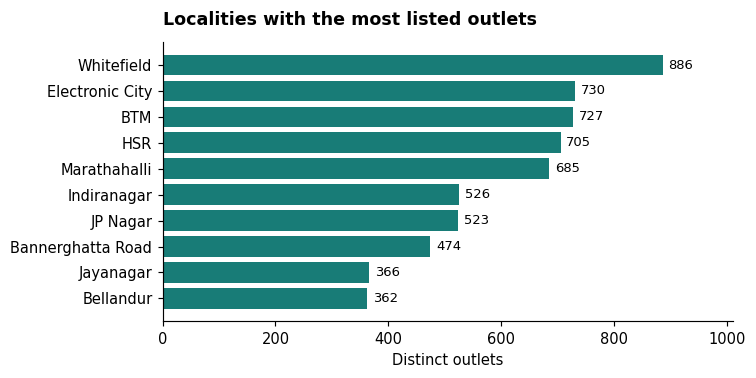

In [4]:
hotspots = outlets.location.value_counts().head(10)
fig, ax = plt.subplots(figsize=(7.3, 3.7))
bars = ax.barh(hotspots.index[::-1], hotspots.values[::-1], color=TEAL)
ax.bar_label(bars, padding=4, fontsize=9)
ax.set(xlabel="Distinct outlets", title="Localities with the most listed outlets", xlim=(0, hotspots.max()*1.14))
plt.tight_layout()
plt.show()

## Cuisine supply and ratings
Each outlet contributes once to each cuisine it lists. The word cloud counts outlets, so an outlet serving two cuisines contributes to both. The heatmap covers the six most common cuisines and six busiest localities. A blank cell has fewer than ten rated outlets.

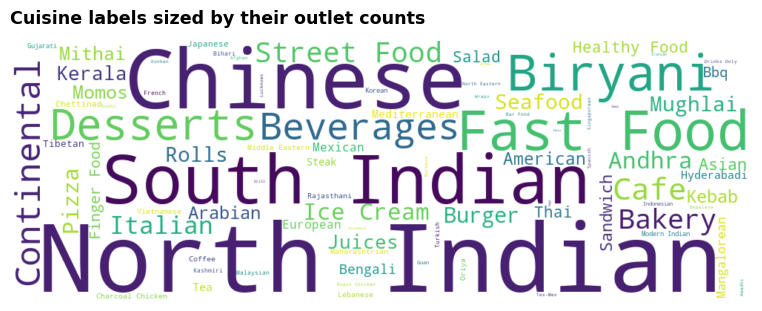

In [5]:
from wordcloud import WordCloud

cuisine_rows = outlets.assign(cuisine=outlets.cuisines.str.split(",")).explode("cuisine").reset_index()
cuisine_rows["cuisine"] = cuisine_rows.cuisine.str.strip().str.title()
cuisine_rows = cuisine_rows.dropna(subset=["cuisine"]).drop_duplicates(["outlet_id", "cuisine"])
counts = cuisine_rows.cuisine.value_counts()
cloud = WordCloud(width=1000, height=350, background_color="white", colormap="viridis",
                  collocations=False, random_state=42).generate_from_frequencies(counts.to_dict())
fig, ax = plt.subplots(figsize=(8, 3))
ax.imshow(cloud, interpolation="bilinear")
ax.set_title("Cuisine labels sized by their outlet counts")
ax.axis("off")
plt.tight_layout()
plt.show()

,rated_outlets,mean_rating
cuisine,,
North Indian,3922,3.57
Chinese,2877,3.55
South Indian,1651,3.57
Fast Food,1635,3.56
Biryani,1302,3.52
Desserts,995,3.79
Beverages,883,3.73
Continental,833,3.89
Cafe,673,3.80


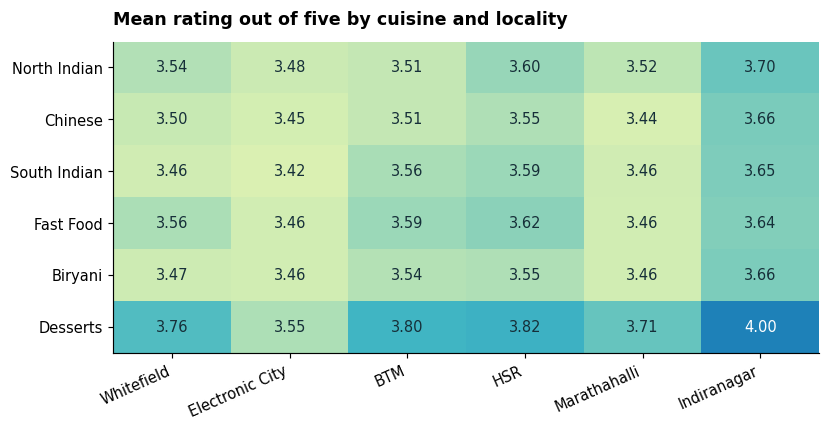

In [6]:
cuisine_stats = cuisine_rows.groupby("cuisine").rating.agg(rated_outlets="count", mean_rating="mean")
display(cuisine_stats.loc[counts.head(10).index].round(2))
grouped = cuisine_rows.groupby(["cuisine", "location"]).rating.agg(["mean", "count"])
matrix = grouped["mean"].where(grouped["count"] >= 10).unstack().reindex(
    index=counts.head(6).index, columns=hotspots.head(6).index)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.imshow(matrix, cmap="YlGnBu", vmin=3.2, vmax=4.4, aspect="auto")
ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=24, ha="right")
ax.set_yticks(range(len(matrix)), matrix.index)
for i, row in enumerate(matrix.to_numpy()):
    for j, value in enumerate(row):
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if value > 3.95 else "#162f39")
ax.set_title("Mean rating out of five by cuisine and locality")
plt.tight_layout()
plt.show()

## Is a higher price associated with a higher rating?
Compute a rank correlation among outlets with both fields. The price-band table includes sample sizes so the small premium segment can be read in context. The measurements are observational.

,outlets,median_rating
band,,
1-300,3293,3.5
301-600,3880,3.6
601-1000,1493,3.8
1001+,773,4.1


Spearman correlation: 0.280 across 9,439 outlets.


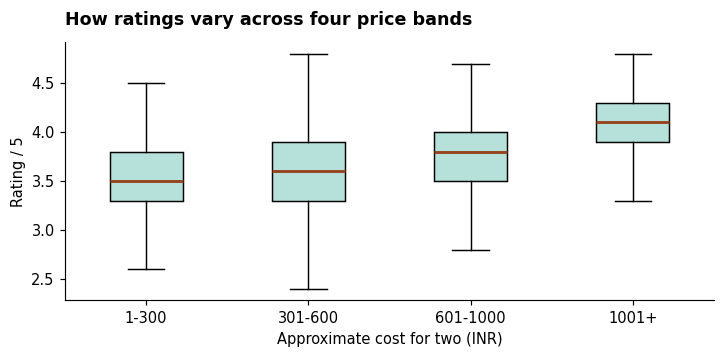

In [7]:
pairs = outlets.dropna(subset=["rating", "cost_for_two_inr"]).copy()
bands = ["1-300", "301-600", "601-1000", "1001+"]
pairs["band"] = pd.cut(pairs.cost_for_two_inr, [0, 300, 600, 1000, np.inf], labels=bands)
price_table = pairs.groupby("band", observed=True).rating.agg(outlets="count", median_rating="median")
rho = pairs.rating.corr(pairs.cost_for_two_inr, method="spearman")
display(price_table)
print(f"Spearman correlation: {rho:.3f} across {len(pairs):,} outlets.")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot([pairs.loc[pairs.band == band, "rating"] for band in bands],
           tick_labels=bands, showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#b6e0da"}, medianprops={"color": "#964520", "linewidth": 2})
ax.set(xlabel="Approximate cost for two (INR)", ylabel="Rating / 5", title="How ratings vary across four price bands")
plt.tight_layout()
plt.show()

In [8]:
print(f"Most listed locality: {hotspots.index[0]} ({hotspots.iloc[0]:,} outlets)")
print(f"Most listed cuisine: {counts.index[0]} ({counts.iloc[0]:,} outlets)")
print(f"Outlets without a usable rating: {outlets.rating.isna().sum():,}")

Most listed locality: Whitefield (886 outlets)
Most listed cuisine: North Indian (5,033 outlets)
Outlets without a usable rating: 3,016


## Five actions for a restaurant discovery platform

1. Start partner outreach in Whitefield, which has 886 distinct outlets in the file. Track signed partners per 50 contacts before extending the pilot to Electronic City (730).
2. Build a North Indian cuisine filter and locality pages. Its 5,033 outlets give users a sizeable selection. Measure how often a search leads to a menu view.
3. Feature a small dessert guide. Dessert-labelled outlets average 3.79/5 across 995 rated outlets, compared with 3.57 across 3,922 rated North Indian outlets. Some outlets appear in both groups. Check menu freshness before featuring them.
4. Show cost for two on discovery cards and offer price filters. The median rating rises from 3.5 at INR 300 or less to 4.1 above INR 1,000, but the rank correlation is only 0.28. Keep budget filters available alongside rating filters.
5. Invite first reviews on the 3,016 unrated outlets. Mark them as awaiting reviews and track the share that receives a first verified rating over a month.

The outlet key can split one venue if its address was entered differently. Rankings describe this historical listing file and depend on the available ratings.